# 2026-10-29 OpenCV 기본 배열 연산

## flip, repeat, transpose 확인

In [13]:
# 공통부분이기 때문에 실습을 새로운 notebook에서 할때마다 복사해서 실행
import sys
sys.path.append('../multi_info/common') # 모듈이 존재하는 path를 추가
import cvnb
import cv2

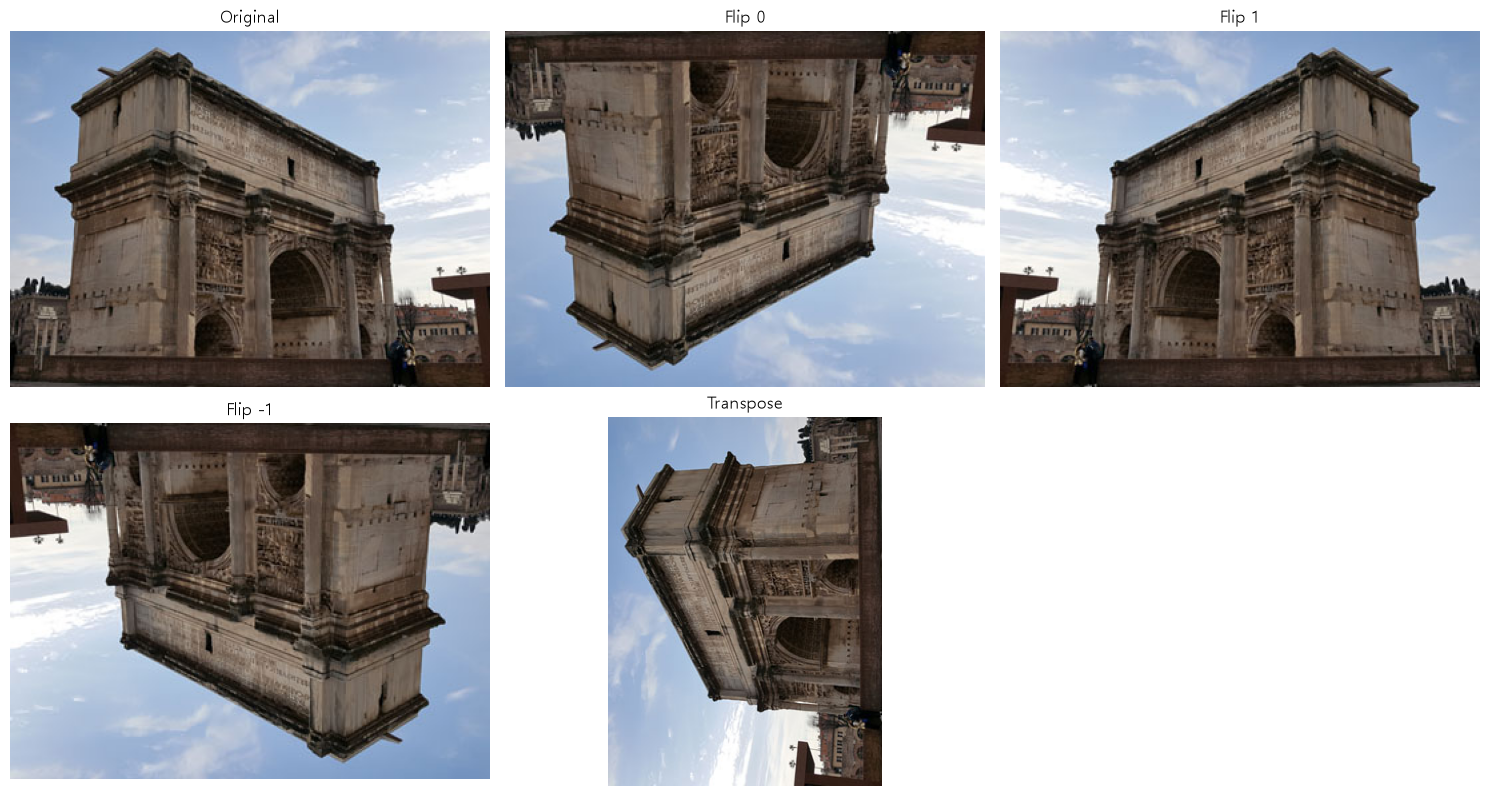

In [14]:
import cv2
import matplotlib.pyplot as plt
from pathlib import Path

# 이미지 불러오기
image_path = Path("../multi_info/images/flip_test.jpg")

if not image_path.is_file():
    raise FileNotFoundError(f"이미지 파일을 찾을 수 없습니다: {image_path.resolve()}")

image = cv2.imread(str(image_path), cv2.IMREAD_COLOR)

if image is None:
    raise Exception("영상 파일 읽기 오류 발생")

# 이미지 반전
flip0 = cv2.flip(image, 0)
flip1 = cv2.flip(image, 1)
flip_1 = cv2.flip(image, -1)

# 이미지 전치
trans = cv2.transpose(image)

# 결과 출력
images = [image, flip0, flip1, flip_1, trans]
titles = ["Original", "Flip 0", "Flip 1", "Flip -1", "Transpose"]

plt.figure(figsize=(15, 8))

for i, (img, title) in enumerate(zip(images, titles)):
    plt.subplot(2, 3, i + 1)
    plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    plt.title(title)
    plt.axis("off")

plt.tight_layout()
plt.show()

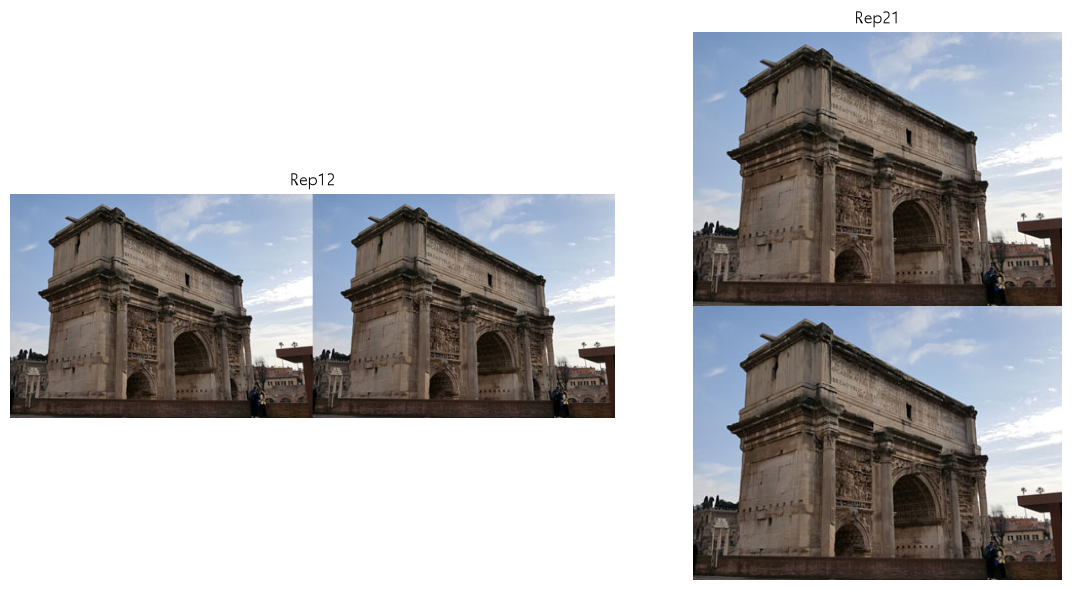

In [15]:
import cv2
import matplotlib.pyplot as plt

rep_image12 = cv2.repeat(image, 1, 2) # x축으로 반복
rep_image21 = cv2.repeat(image, 2, 1) # y축으로 반복

plt.figure(figsize=(12, 6))

plt.subplot(1, 2, 1)
plt.imshow(cv2.cvtColor(rep_image12, cv2.COLOR_BGR2RGB))
plt.title("Rep12")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(cv2.cvtColor(rep_image21, cv2.COLOR_BGR2RGB))
plt.title("Rep21")
plt.axis("off")

plt.tight_layout()
plt.show()

- opencv의 transpose 확인

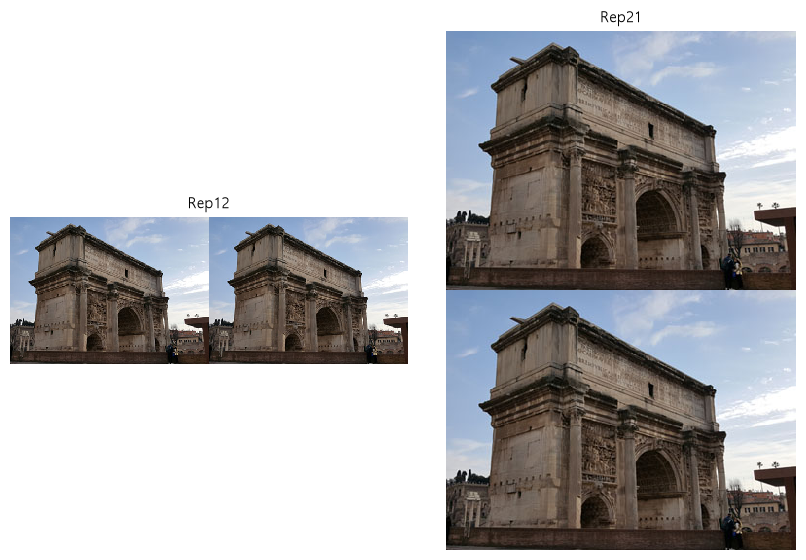

In [16]:
rep_image12 = cv2.repeat(image, 1, 2) # x축으로 반복
rep_image21 = cv2.repeat(image, 2, 1) # y축으로 반복
cv2.imshow("Rep12", rep_image12)
cv2.imshow("Rep21", rep_image21)

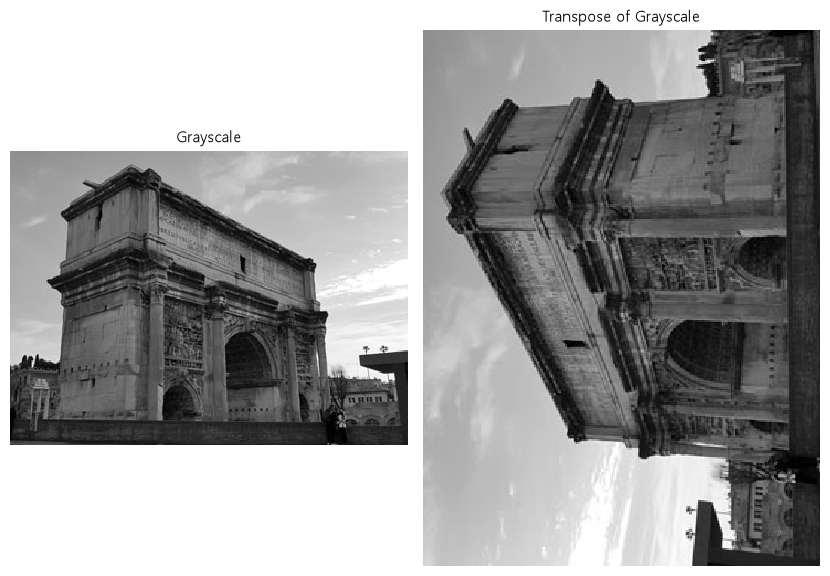

In [17]:
tr_cv_gr = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
cv2.imshow("Grayscale", tr_cv_gr)
trans_cv_gr = cv2.transpose(tr_cv_gr)
cv2.imshow("Transpose of Grayscale", trans_cv_gr)

In [18]:
color_img = cv2.imread("../multi_info/images/logo.jpg", cv2.IMREAD_COLOR)
print(f"image information: {color_img.shape}, {color_img.shape[1]}x{color_img.shape[0]}")

split_img = cv2.split(color_img)
print(type(split_img), f"type {type(split_img[0])}")
#print(f"image information: {split_img.shape}, {split_img.shape[1]}x{split_img.shape[0]}")

image information: (308, 250, 3), 250x308
<class 'tuple'> type <class 'numpy.ndarray'>


image information: (308, 250, 3), 250x308
<class 'numpy.ndarray'> <class 'numpy.ndarray'>
image information: (3, 308, 250), 308x3


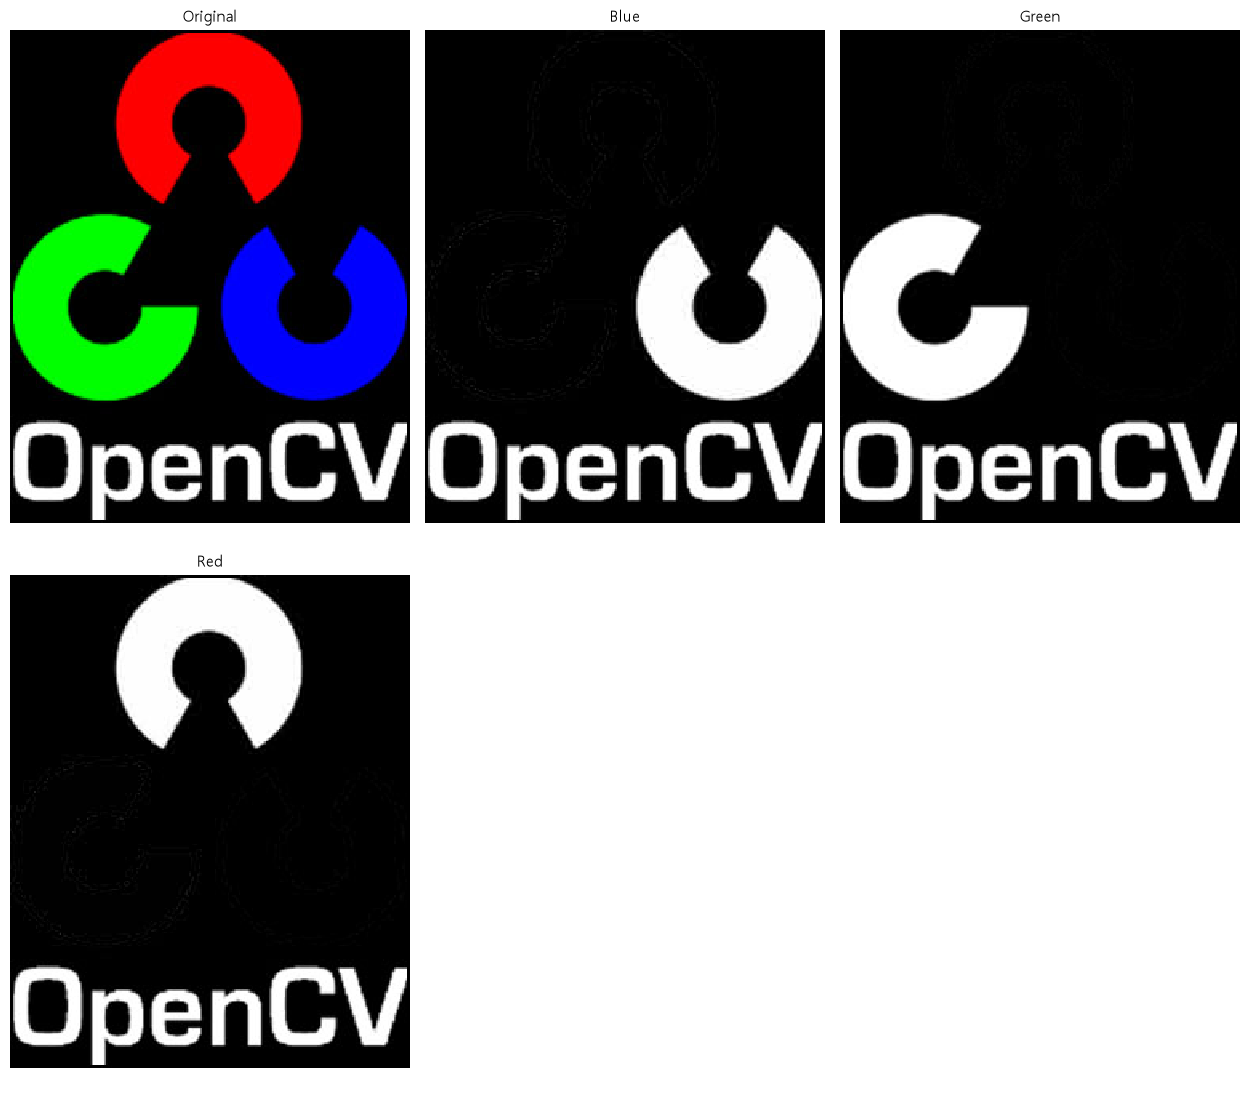

In [19]:
import numpy as np
color_img = cv2.imread("../multi_info/images/logo.jpg", cv2.IMREAD_COLOR)
print(f"image information: {color_img.shape}, {color_img.shape[1]}x{color_img.shape[0]}")

split_img = np.array(cv2.split(color_img))
print(type(split_img), f"{type(split_img[0])}")
print(f"image information: {split_img.shape}, {split_img.shape[1]}x{split_img.shape[0]}")

cv2.imshow("Original", color_img)
cv2.imshow("Blue", split_img[0])
cv2.imshow("Green", split_img[1])
cv2.imshow("Red", split_img[2])

- 산술연산 + 비트 연산

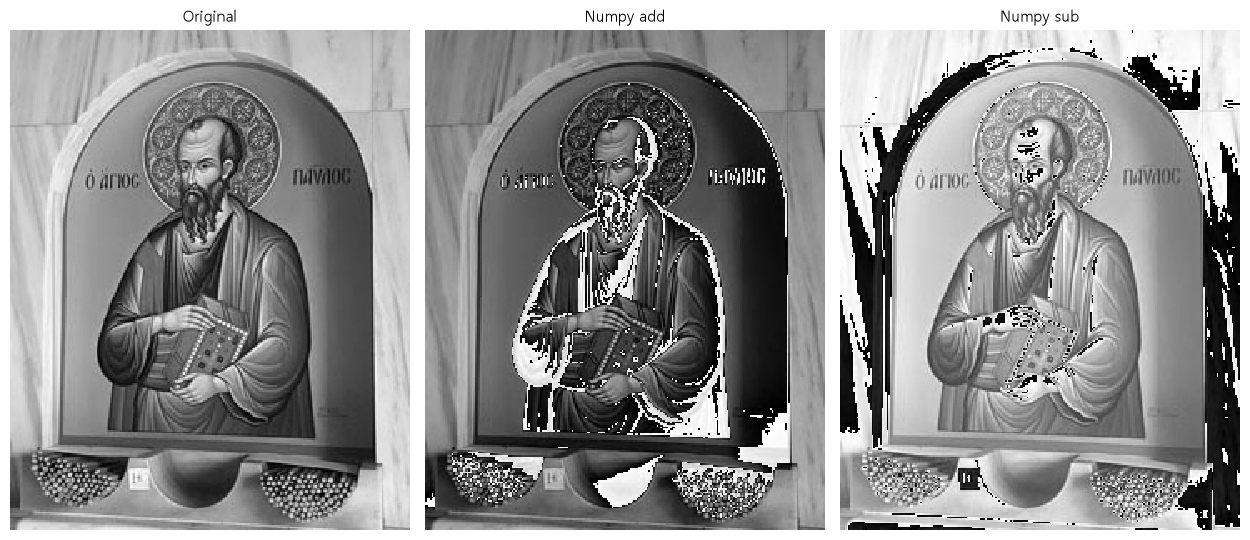

In [21]:
image = cv2.imread("../multi_info/images/pixel.jpg", cv2.IMREAD_GRAYSCALE)
cv2.imshow("Original", image)

add_img = image + 200
cv2.imshow("Numpy add", add_img)
sub_img = image - 200
cv2.imshow("Numpy sub", sub_img)

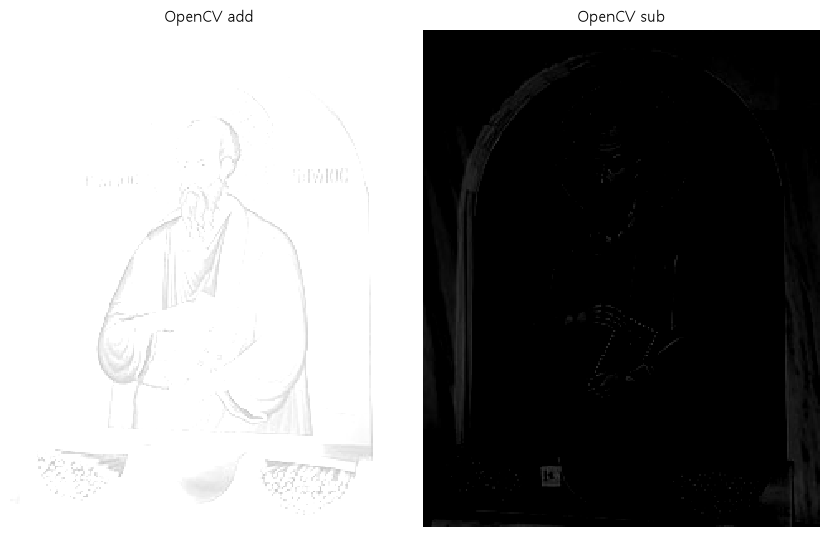

In [22]:
cv_add_img = cv2.add(image, 200)
cv2.imshow("OpenCV add", cv_add_img)
cv_sub_img = cv2.subtract(image, 200)
cv2.imshow("OpenCV sub", cv_sub_img)

image: (300, 240), mask: (300, 240)


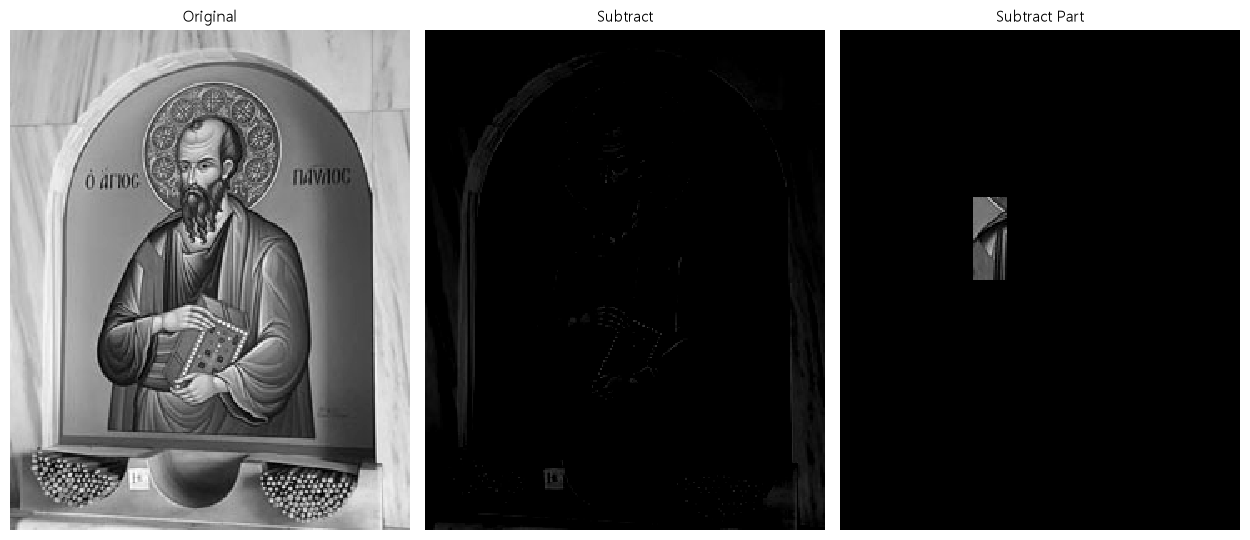

In [23]:
mask = np.zeros_like(image)
print(f"image: {image.shape}, mask: {mask.shape}")
mask[100:150, 80:100] = 1
cv_sub_img_part = cv2.subtract(image, 20, mask=mask)
cv2.imshow("Original", image)
cv2.imshow("Subtract", cv_sub_img)
cv2.imshow("Subtract Part", cv_sub_img_part)

- bitwise 연산을 통해서 원하는 부분만 교체

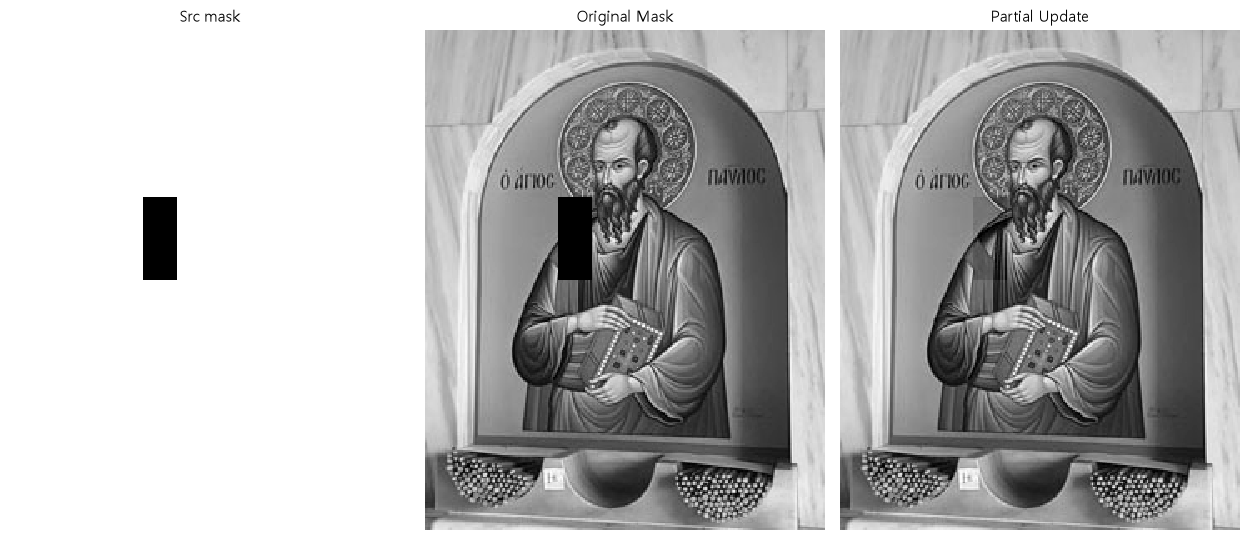

In [27]:
mask = np.zeros_like(image)
mask[100:150, 80:100] = 255

src_mask = cv2.bitwise_not(mask)
src_image_mask = cv2.bitwise_and(image, src_mask)
cv2.imshow("Src mask", src_mask)
cv2.imshow("Original Mask", src_image_mask)
target = src_image_mask + cv_sub_img_part
cv2.imshow("Partial Update", target)